# 03 — Linear models (FD001)

The linear baseline every other model is compared against: OLS on the raw readings and Elastic Net on the 57 features. Both are scored on the same 100 fixed validation points.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from load_data import ALL_SENSORS, SETTINGS, load_test, load_train
from features import FEATURES, add_rolling_features
from evaluation import VAL_ENGINES, mae, rmse, split_train_val, test_points, validation_points

## 1. Data

Split by **engine**, never by row: rows of one engine are near-copies, so a row split would put the same engine on both sides. The 20 validation engines are the ones in `validation_cutoffs.csv`; the other 80 are for training.

A test engine is scored once, at its last row. Validation copies this with 5 fixed cut-off cycles per validation engine, so 100 scored points.

In [2]:
train = add_rolling_features(load_train())
test = add_rolling_features(load_test())
train_df, val_df = split_train_val(train)
val_pts = validation_points(val_df)
test_pts = test_points(test)

print("train_df:", len(train_df), "rows,", train_df["engine_id"].nunique(), "engines")
print("val_df:  ", len(val_df), "rows,", val_df["engine_id"].nunique(), "engines")
print("val_pts:", len(val_pts), "| test_pts:", len(test_pts))
print("VAL_ENGINES:", [int(e) for e in VAL_ENGINES])
print("engines on both sides:", set(train_df["engine_id"]) & set(val_df["engine_id"]))

train_df: 16390 rows, 80 engines
val_df:   4241 rows, 20 engines
val_pts: 100 | test_pts: 100
VAL_ENGINES: [8, 9, 13, 18, 37, 46, 48, 50, 55, 62, 64, 69, 72, 74, 76, 84, 85, 87, 90, 95]
engines on both sides: set()


## 2. Two feature sets

- **V1:** the 24 raw columns (3 settings, 21 sensors) at the current cycle only.
- **V2:** `FEATURES` from notebook 02: `cycle`, the 14 useful sensors and their 42 rolling features.

In [3]:
V1 = SETTINGS + ALL_SENSORS
V2 = FEATURES
print("V1:", len(V1), "columns | V2:", len(V2), "columns")

V1: 24 columns | V2: 57 columns


## 3. Two models, fixed settings

- **OLS on V1:** plain least squares.
- **Elastic Net on V2:** least squares plus a penalty on the coefficients. `alpha` sets how strong the penalty is; `l1_ratio=0.5` mixes L1 (can set a coefficient to exactly 0) and L2 (shrinks it). These settings were picked on validation in our earlier work (alpha 0.001–1, l1_ratio 0.2 / 0.5 / 0.8).

Both fit on every row of the 80 training engines, with the true RUL as target. The scaler sits inside the pipeline, so it learns the mean and std from training rows only.

In [4]:
feature_sets = {"ols_v1": V1, "elastic_net_v2": V2}
models = {
    "ols_v1": make_pipeline(StandardScaler(), LinearRegression()),
    "elastic_net_v2": make_pipeline(StandardScaler(), ElasticNet(alpha=1, l1_ratio=0.5, max_iter=50_000)),
}
for name, model in models.items():
    model.fit(train_df[feature_sets[name]], train_df["rul"])

## 4. Validation scores

MAE and RMSE in cycles at the 100 validation points.

In [5]:
val_pred = {name: model.predict(val_pts[feature_sets[name]]) for name, model in models.items()}

pd.DataFrame([
    {"model": name, "features": len(feature_sets[name]),
     "mae": mae(val_pts["rul"], pred), "rmse": rmse(val_pts["rul"], pred)}
    for name, pred in val_pred.items()
]).round(2)

,model,features,mae,rmse
0,ols_v1,24,32.86,42.92
1,elastic_net_v2,57,31.66,41.77


Elastic Net on the 57 features is better on both metrics, so it is the linear baseline to beat.

## 5. Underfitting check

RMSE on every training row vs every validation row (not only the 100 points).

In [6]:
pd.DataFrame([
    {"model": name,
     "train_rmse": rmse(train_df["rul"], model.predict(train_df[feature_sets[name]])),
     "val_rmse_all_rows": rmse(val_df["rul"], model.predict(val_df[feature_sets[name]]))}
    for name, model in models.items()
]).round(2)

,model,train_rmse,val_rmse_all_rows
0,ols_v1,43.31,49.72
1,elastic_net_v2,39.30,47.25


The training error is high too (about 39–43 cycles), so the linear model mostly underfits (high bias): a straight line can't follow the "flat, then steep" sensor drift seen in notebook 01.

## 6. Diagnostics for Elastic Net

Residual = true RUL − predicted RUL, at the 100 validation points.

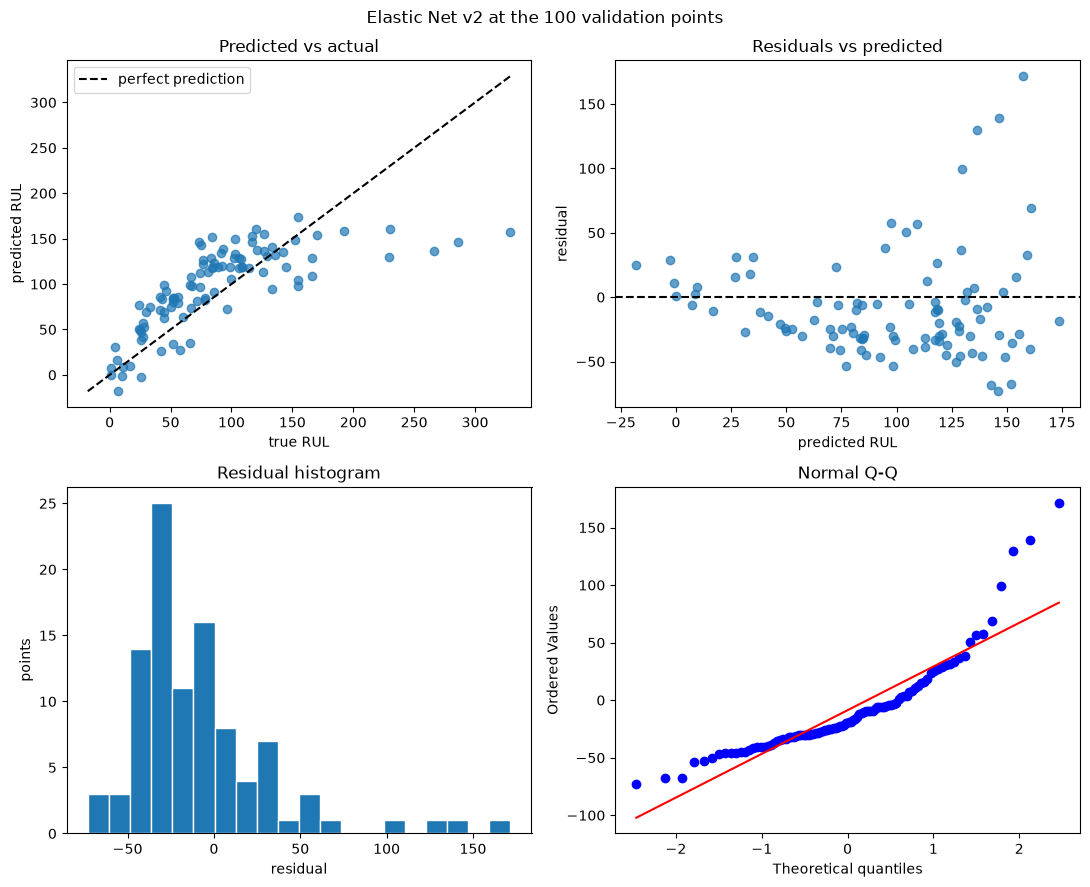

In [7]:
y = val_pts["rul"]
pred = val_pred["elastic_net_v2"]
residuals = y - pred

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

ax = axes[0, 0]
ax.scatter(y, pred, alpha=0.7)
lim = [min(y.min(), pred.min()), max(y.max(), pred.max())]
ax.plot(lim, lim, "k--", label="perfect prediction")
ax.set(xlabel="true RUL", ylabel="predicted RUL", title="Predicted vs actual")
ax.legend()

ax = axes[0, 1]
ax.scatter(pred, residuals, alpha=0.7)
ax.axhline(0, color="k", linestyle="--")
ax.set(xlabel="predicted RUL", ylabel="residual", title="Residuals vs predicted")

ax = axes[1, 0]
ax.hist(residuals, bins=20, edgecolor="white")
ax.set(xlabel="residual", ylabel="points", title="Residual histogram")

stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q")

fig.suptitle("Elastic Net v2 at the 100 validation points")
plt.tight_layout()
plt.show()

In [8]:
for name, p in val_pred.items():
    print(f"{name}: {(p < 0).sum()} negative predictions")

ols_v1: 4 negative predictions
elastic_net_v2: 3 negative predictions


- **Predicted vs actual:** predictions stop at about 174 while true RUL goes up to 329, so engines far from failure are predicted too low.
- **Residuals vs predicted:** the residuals are not a flat band around 0. Large positive residuals (true RUL much higher than predicted) come from engines far from failure; near failure the model predicts too much life left.
- **Histogram and Q-Q:** the residuals are skewed to the right with a long tail, so they are not normal. The linear-regression assumptions do not hold well here.
- **Negative predictions:** RUL can't be below 0, but we don't clip them, so the scores show the model as it is.

## 7. Coefficients

The features are scaled, so coefficient sizes can be compared: each one is the change in predicted RUL for one standard deviation more of that feature.

In [9]:
coef = pd.Series(models["elastic_net_v2"][-1].coef_, index=FEATURES)
print("coefficients exactly 0:", (coef == 0).sum(), "of", len(coef))
print("removed by L1:", coef[coef == 0].index.tolist())
coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(2)

coefficients exactly 0: 7 of 57
removed by L1: ['sensor_8_mean', 'sensor_9_slope', 'sensor_11_std', 'sensor_13_mean', 'sensor_17_std', 'sensor_17_slope', 'sensor_21_std']


cycle            -14.35
sensor_3_mean     -2.58
sensor_2_mean     -2.47
sensor_4_mean     -2.39
sensor_11         -2.34
sensor_11_mean    -2.20
sensor_4          -2.18
sensor_7_mean      2.07
sensor_7           1.99
sensor_9_mean     -1.97
dtype: float64

`cycle` (engine age) has by far the largest coefficient: an older engine is predicted to have less life left. L1 set 7 features to exactly 0: they add little once the other features are in the model.

## 8. Save predictions

Predictions at the 100 validation points and the 100 test points, for notebook 05. No test scoring here: the test answers are used only once, in notebook 05.

In [10]:
val_out = val_pts[["engine_id", "cycle"]].copy()
test_out = test_pts[["engine_id"]].copy()
for name, model in models.items():
    val_out[name] = val_pred[name]
    test_out[name] = model.predict(test_pts[feature_sets[name]])

val_out.to_csv("../results/val_predictions_linear.csv", index=False)
test_out.to_csv("../results/test_predictions_linear.csv", index=False)
print("val:", val_out.shape, "| test:", test_out.shape)
test_out.head(3).round(2)

val: (100, 4) | test: (100, 3)


,engine_id,ols_v1,elastic_net_v2
30,1,158.47,157.46
79,2,121.28,135.79
205,3,85.13,83.91
